# Encoder: fine-tuned XLM-R

Fine-tunes a multilingual encoder on the **same fixed split and sample as the baseline**: `splits/train_folds.csv` with fold 0 as validation, and the same 50k training sample (stratified by label × language, seed 42). The macro-F1 scores can be compared directly with the TF-IDF baseline. Texts longer than 512 tokens are split into overlapping windows, and a text's prediction is the mean of its window probabilities.

**Kaggle setup**
- *Settings → Accelerator*: GPU T4 ×2. *Settings → Internet*: on (to download the model and the split file).
- *Add Input*: the competition `ai-generated-text-detection-hw3-ucu-ai-2026`.
- First run with `SMOKE = True` (a few minutes), then set `SMOKE = False` and use *Save Version → Save & Run All* so it runs in the background. Outputs go to `/kaggle/working/encoder/`.

In [1]:
import glob
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from datasets import Dataset
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, Trainer,
                          TrainingArguments, set_seed)

SEED = 42
set_seed(SEED)

LABELS = ["human", "ai", "fusion"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
VAL_FOLD = 0

SMOKE = False  # True: tiny end-to-end run to check the pipeline; False: the real run

CONFIG = {
    "model_name": "FacebookAI/xlm-roberta-base",
    "n_train": 50_000,        # same fixed sample as the baseline search
    "max_len": 512,           # tokens per window
    "stride": 128,            # tokens shared by consecutive windows
    "max_train_windows": 4,   # windows per training text, so long texts do not dominate
    "epochs": 2,
    "lr": 2e-5,
    "batch_size": 16,         # per GPU
    "warmup_frac": 0.06,
    "weight_decay": 0.01,
}
N_EVAL_SMOKE = 2_000  # validation and test texts used in smoke mode
if SMOKE:
    CONFIG.update(n_train=2_000, epochs=1)

ON_KAGGLE = Path("/kaggle/input").exists()
OUT_DIR = Path("/kaggle/working/encoder" if ON_KAGGLE else "../outputs/encoder")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"torch {torch.__version__} | transformers {transformers.__version__} | "
      f"GPUs: {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())] or 'none'}")

torch 2.11.0+cu130 | transformers 5.20.2 | GPUs: ['Tesla T4', 'Tesla T4']


## 1. Data
The competition files come from the attached Kaggle input (or the local kagglehub cache). The fold assignment comes from the repo's `splits/train_folds.csv` (downloaded from GitHub on Kaggle). `stratified_sample` is the same function as in `baseline_tfidf.ipynb`, so the 50k training sample is the same one the baseline used.

In [2]:
COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"
LOCAL_SPLIT = Path("../splits/train_folds.csv")
SPLIT_URL = "https://raw.githubusercontent.com/ruzhylopv/aiGeneratedTextDetection-ai-hw3/main/splits/train_folds.csv"


def find_data_dir():
    """Competition folder: the attached Kaggle input if present, otherwise the local kagglehub cache."""
    hits = sorted(glob.glob("/kaggle/input/**/train.csv", recursive=True), key=lambda p: COMPETITION not in p)
    if hits:
        return Path(hits[0]).parent
    import kagglehub
    return Path(kagglehub.competition_download(COMPETITION))


def stratified_sample(df, n, seed=SEED):
    """Fixed random sample of n rows with the label × language shares of df (all rows if n >= len(df))."""
    if n >= len(df):
        return df.reset_index(drop=True)
    strata = df["label"] + "|" + df["lang"]
    return (df.groupby(strata, group_keys=False)
              .sample(frac=n / len(df), random_state=seed)
              .reset_index(drop=True))


DATA_DIR = find_data_dir()
folds = pd.read_csv(LOCAL_SPLIT if LOCAL_SPLIT.exists() else SPLIT_URL)
train = pd.read_csv(DATA_DIR / "train.csv").merge(folds, on="id", validate="1:1")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

train_fold = train[train["fold"] != VAL_FOLD].reset_index(drop=True)
val_fold = train[train["fold"] == VAL_FOLD].reset_index(drop=True)
del train
train_sample = stratified_sample(train_fold, CONFIG["n_train"])
if SMOKE:
    val_fold = val_fold.sample(N_EVAL_SMOKE, random_state=SEED).reset_index(drop=True)
    test = test.head(N_EVAL_SMOKE)

pd.DataFrame({"texts": {"train sample": len(train_sample), "validation": len(val_fold), "test": len(test)}}).T

,train sample,validation,test
texts,50000,27236,25000


## 2. Windows for long texts
Each text is tokenized into windows of `max_len` tokens, with `stride` tokens of overlap between neighbours. Training uses the first `max_train_windows` windows of each text, each labelled with the text's label. For `fusion` texts not every window has to contain rewritten text, so window labels are noisy. Validation and test use all windows. `doc` maps a window back to its text, and `position` is its index within that text.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"])


def window_batch(batch, indices, max_windows):
    """Tokenize a batch of texts into overlapping windows, keeping at most max_windows per text."""
    enc = tokenizer(batch["text"], truncation=True, max_length=CONFIG["max_len"], stride=CONFIG["stride"],
                    return_overflowing_tokens=True)
    local_doc = np.asarray(enc["overflow_to_sample_mapping"])
    position = np.arange(len(local_doc)) - np.searchsorted(local_doc, local_doc)
    keep = np.flatnonzero(position < max_windows)
    out = {key: [enc[key][i] for i in keep] for key in ("input_ids", "attention_mask")}
    out["doc"] = [indices[local_doc[i]] for i in keep]
    out["position"] = position[keep].tolist()
    if "label" in batch:
        out["labels"] = [LABEL2ID[batch["label"][local_doc[i]]] for i in keep]
    return out


def make_windows(df, name, max_windows=None):
    """Dataset of token windows for the texts of df (with labels if df has them)."""
    columns = [c for c in ("text", "label") if c in df.columns]
    return Dataset.from_pandas(df[columns], preserve_index=False).map(
        window_batch, batched=True, with_indices=True, remove_columns=columns,
        fn_kwargs={"max_windows": max_windows or math.inf}, desc=f"{name}: windows")


def window_index(ds):
    """The doc and position columns of a window dataset as a DataFrame."""
    return ds.select_columns(["doc", "position"]).to_pandas()


texts = {"train": train_sample, "val": val_fold, "test": test}
windows = {"train": make_windows(train_sample, "train", CONFIG["max_train_windows"]),
           "val": make_windows(val_fold, "val"),
           "test": make_windows(test, "test")}

window_stats = pd.DataFrame([
    {"split": split, "texts": len(texts[split]), "windows": len(ds),
     "windows / text": len(ds) / len(texts[split]),
     "texts > 1 window %": 100 * (window_index(ds)["position"] == 1).sum() / len(texts[split])}
    for split, ds in windows.items()]).set_index("split")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

train: windows:   0%|          | 0/50000 [00:00<?, ? examples/s]

val: windows:   0%|          | 0/27236 [00:00<?, ? examples/s]

test: windows:   0%|          | 0/25000 [00:00<?, ? examples/s]

In [4]:
window_stats.round(2)

,texts,windows,windows / text,texts > 1 window %
split,,,,
train,50000,104407,2.09,63.40
val,27236,61765,2.27,63.37
test,25000,55921,2.24,61.45


## 3. Fine-tuning
Pretrained encoder with a new 3-class head, trained on all training windows: AdamW, linear decay after warm-up, fp16 (the T4 has no bf16). With two GPUs the notebook's `Trainer` uses both (DataParallel), so the effective batch is `batch_size` × GPUs. Nothing is fitted on validation or test rows: the tokenizer is pretrained and the validation fold is only used for scoring.

In [5]:
def build_trainer(train_ds):
    """Trainer for the pretrained encoder with a fresh 3-class head."""
    model = AutoModelForSequenceClassification.from_pretrained(
        CONFIG["model_name"], num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=LABEL2ID)
    n_gpus = max(1, torch.cuda.device_count())
    total_steps = CONFIG["epochs"] * math.ceil(len(train_ds) / (CONFIG["batch_size"] * n_gpus))
    args = TrainingArguments(
        output_dir=str(OUT_DIR / "checkpoints"),
        num_train_epochs=CONFIG["epochs"],
        learning_rate=CONFIG["lr"],
        per_device_train_batch_size=CONFIG["batch_size"],
        per_device_eval_batch_size=4 * CONFIG["batch_size"],
        warmup_steps=int(CONFIG["warmup_frac"] * total_steps),
        weight_decay=CONFIG["weight_decay"],
        lr_scheduler_type="linear",
        fp16=torch.cuda.is_available(),
        eval_strategy="no",
        save_strategy="no",
        logging_steps=50,
        report_to="none",
        seed=SEED,
        dataloader_num_workers=2,
    )
    return Trainer(model=model, args=args, train_dataset=train_ds, processing_class=tokenizer,
                   data_collator=DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8))


trainer = build_trainer(windows["train"])
train_output = trainer.train()
trainer.save_model(str(OUT_DIR / "model"))

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning

Step,Training Loss
50,2.272180
100,2.060933
150,1.707857
200,1.458216
250,1.297383
300,1.029326
350,1.054646
400,0.940348
450,0.990086
500,0.933108


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

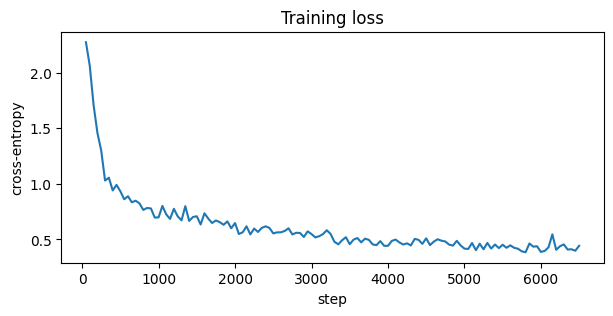

In [6]:
loss_log = pd.DataFrame([row for row in trainer.state.log_history if "loss" in row])
ax = loss_log.plot(x="step", y="loss", legend=False, figsize=(7, 3))
ax.set(title="Training loss", xlabel="step", ylabel="cross-entropy");

## 4. Validation: from windows to texts
Two ways to turn window probabilities into one prediction per text, on the same trained model:
- **first**: first window only. This is plain truncation to 512 tokens, the reference for long-text handling.
- **mean**: mean of the probabilities of all the text's windows.

The baseline row is the best TF-IDF configuration from `baseline_tfidf.ipynb` (word+char LinearSVC, C=1, balanced; LinearSVC results as of commit 31e9846), trained on the same 50k sample and scored on the same full validation fold. In smoke mode the validation set is a 2k subsample, so only the full run can be compared with the baseline.

In [7]:
BASELINE_SCORES = {"macro_f1": 0.8599, "f1_human": 0.7940, "f1_ai": 0.9831, "f1_fusion": 0.8026}
AGGREGATIONS = ["first", "mean"]


def window_probs(trainer, ds):
    """Softmax class probabilities of every window."""
    logits = trainer.predict(ds).predictions
    return torch.softmax(torch.from_numpy(logits).float(), dim=-1).numpy()


def text_probs(probs, ds, n_texts, how):
    """Per-text class probabilities: the first window only ("first") or the mean over all windows ("mean")."""
    frame = pd.DataFrame(probs, columns=LABELS).join(window_index(ds))
    if how == "first":
        frame = frame[frame["position"] == 0]
    out = frame.groupby("doc")[LABELS].mean().reindex(range(n_texts))
    assert not out.isna().any().any(), "some texts have no window"
    return out.to_numpy()


def to_labels(probs):
    """Class names of the most probable class per row."""
    return np.array(LABELS)[probs.argmax(axis=1)]


def score(y_true, y_pred):
    """Macro-F1 and per-class F1."""
    per_class = f1_score(y_true, y_pred, labels=LABELS, average=None)
    return {"macro_f1": f1_score(y_true, y_pred, average="macro"),
            **{f"f1_{label}": f1 for label, f1 in zip(LABELS, per_class)}}


y_val = val_fold["label"].to_numpy()
val_window_probs = window_probs(trainer, windows["val"])
val_probs = {how: text_probs(val_window_probs, windows["val"], len(val_fold), how) for how in AGGREGATIONS}

model_tag = CONFIG["model_name"].split("/")[-1]
comparison = pd.DataFrame(
    [{"model": "TF-IDF baseline", "long texts": "n/a", **BASELINE_SCORES}]
    + [{"model": model_tag, "long texts": how, **score(y_val, to_labels(val_probs[how]))} for how in AGGREGATIONS])

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [8]:
comparison.round(4)

,model,long texts,macro_f1,f1_human,f1_ai,f1_fusion
0,TF-IDF baseline,n/a,0.8599,0.7940,0.9831,0.8026
1,xlm-roberta-base,first,0.8640,0.7828,0.9880,0.8211
2,xlm-roberta-base,mean,0.9020,0.8362,0.9901,0.8797


In [9]:
def scores_by(df, y_pred, column):
    """Macro-F1 within each value of a column (e.g. lang, domain)."""
    rows = [{column: value, "texts": len(group), "macro_f1": f1_score(group["label"], group["pred"], average="macro")}
            for value, group in df.assign(pred=y_pred).groupby(column)]
    return pd.DataFrame(rows).set_index(column)


val_pred = to_labels(val_probs["mean"])
pd.concat({column: scores_by(val_fold, val_pred, column) for column in ("lang", "domain")}).round(4)

texts  macro_f1
lang   de-DE                    5278    0.9089
       en-EN                   21958    0.9001
domain arxiv_papers             1403    0.6233
       blog_authorship_corpus   4135    0.8444
       bundestag                5227    0.9093
       cnn_news                 4425    0.9743
       euro_court_cases         2702    0.7785
       gutenberg                 731    0.7097
       house_of_commons         3121    0.9195
       student_essays           5492    0.9193

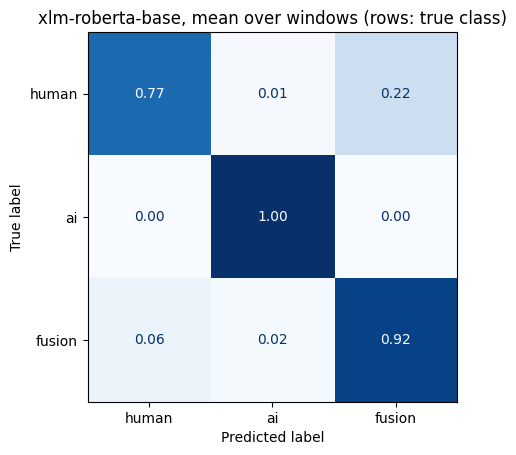

In [10]:
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, labels=LABELS, normalize="true", values_format=".2f",
                                        cmap="Blues", colorbar=False)
plt.title(f"{model_tag}, mean over windows (rows: true class)");

## 5. Test predictions and submission
The test set uses the "mean" aggregation. The text-level probabilities for validation and test are saved with their ids for later ensembling with the baseline and other features. The submission goes through the same format checks as the baseline's. It is only written in the full run, since smoke mode predicts just 2k test texts.

In [11]:
def make_submission(ids, labels, sample):
    """Predictions in sample-submission order, checked against the format rules in COMPETITION.md."""
    sub = sample[["id"]].merge(pd.DataFrame({"id": ids, "label": labels}), on="id", how="left", validate="1:1")
    assert len(sub) == 25_000 and sub["id"].equals(sample["id"]), "rows or order differ from sample_submission.csv"
    assert sub["label"].isin(LABELS).all(), "missing or unknown labels"
    return sub


def save_probs(df, probs, path):
    """Text-level class probabilities with their ids."""
    pd.DataFrame(probs, columns=LABELS).assign(id=df["id"].to_numpy())[["id", *LABELS]].to_csv(path, index=False)


test_probs = text_probs(window_probs(trainer, windows["test"]), windows["test"], len(test), "mean")
save_probs(val_fold, val_probs["mean"], OUT_DIR / f"val_probs_{model_tag}.csv")
save_probs(test, test_probs, OUT_DIR / f"test_probs_{model_tag}.csv")

run_summary = {**CONFIG, "smoke": SMOKE, "train_windows": len(windows["train"]),
               "train_minutes": round(train_output.metrics["train_runtime"] / 60, 1),
               "val_macro_f1_mean": comparison.loc[comparison["long texts"] == "mean", "macro_f1"].item()}
(OUT_DIR / f"run_{model_tag}.json").write_text(json.dumps(run_summary, indent=2))

if SMOKE:
    print("smoke run: submission not written")
else:
    sub = make_submission(test["id"], to_labels(test_probs), sample_submission)
    sub_path = OUT_DIR / f"encoder_{model_tag}_mean.csv"
    sub.to_csv(sub_path, index=False)
    print(f"saved {sub_path} ({len(sub):,} rows)")

saved /kaggle/working/encoder/encoder_xlm-roberta-base_mean.csv (25,000 rows)


In [12]:
# predicted class shares on test should look like the validation ones
pd.DataFrame({"val true %": pd.Series(y_val).value_counts(normalize=True),
              "val pred %": pd.Series(val_pred).value_counts(normalize=True),
              "test pred %": pd.Series(to_labels(test_probs)).value_counts(normalize=True)}).loc[LABELS].mul(100).round(1).T

,human,ai,fusion
val true %,24.5,44.8,30.7
val pred %,20.9,45.3,33.8
test pred %,21.2,52.0,26.8
